# 3-amaliy mashg'ulot: Python, NumPy va OpenCV bilan birinchi qadam
**Qoida:** bugun kodni *yozmaymiz*, faqat ishga tushiramiz va **bitta sonni o'zgartirib** natijani kuzatamiz.
Kataklarni yuqoridan pastga ketma-ket bajaring (▶ tugmasi).

| MATLAB (oldingi darslar) | Python (bugun) |
|---|---|
| `A = zeros(100,100)` | `A = np.zeros((100,100), dtype=np.uint8)` |
| indeks 1 dan boshlanadi | indeks **0** dan boshlanadi |
| `A(26:75, 26:75)` oxiri kiradi | `A[25:75, 25:75]` oxiri **kirmaydi** |
| `imshow(A)` | `plt.imshow(A, cmap="gray")` |
| rang tartibi RGB | OpenCV da **BGR** |

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

print("Kutubxonalar yuklandi! OpenCV versiyasi:", cv2.__version__)

Kutubxonalar yuklandi! OpenCV versiyasi: 5.0.0


## 1-qadam. Tasvir = sonlar jadvali
**Vazifa:** `25` va `75` ni `10` va `90` ga almashtiring. Kvadrat qanday o'zgaradi?

Shakli: (100, 100)


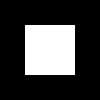

In [ ]:
black_img = np.zeros((100, 100), dtype=np.uint8)
black_img[25:75, 25:75] = 255          # <-- shu sonlarni o'zgartiring
print("Shakli:", black_img.shape)

# Rasmni juda oddiy usulda ko'rsatamiz:
cv2_imshow(black_img)

## 2-qadam. Rangli tasvir: (balandlik, kenglik, 3 kanal)
OpenCV tartibi **B, G, R**. 2-indeks = qizil.
**Vazifa:** `2` ni `0` ga o'zgartiring. Qaysi rang chiqadi?

Shakli: (100, 100, 3)


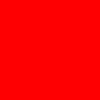

In [ ]:
color_img = np.zeros((100, 100, 3), dtype=np.uint8)
color_img[:, :, 2] = 255               # <-- kanal indeksini o'zgartiring (0, 1, 2)
print("Shakli:", color_img.shape)

# cv2_imshow avtomatik ravishda BGR ranglarni to'g'ri aniqlaydi:
cv2_imshow(color_img)

## 3-qadam. Kanallarni ajratish
**Savol:** qizil tasvirda qaysi kanalning o'rtachasi 255 bo'ladi?

In [ ]:
blue  = color_img[:, :, 0]
green = color_img[:, :, 1]
red   = color_img[:, :, 2]
print("B, G, R o'rtacha:", blue.mean(), green.mean(), red.mean())
print("Har bir kanal shakli:", red.shape)

## 4-qadam. BGR va RGB chalkashligi
Oxirgi tasvirni to'g'ridan-to'g'ri Matplotlib ga bersak, ranglar almashadi.

In [ ]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(color_img)                                    # noto'g'ri: BGR ni RGB deb o'qiydi
plt.title("Xato: BGR to'g'ridan-to'g'ri"); plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))   # to'g'ri
plt.title("To'g'ri: BGR -> RGB"); plt.axis("off")
plt.show()

## 5-qadam. Rang modeli: HSV bilan rang bo'yicha ajratish
3-darsdagi rang modellari endi amalda: yashil rangni **Hue** orqali topamiz.
**Vazifa:** pastki chegara `40` ni `20` ga tushiring. Nima o'zgaradi?

In [ ]:
scene = np.zeros((120, 200, 3), dtype=np.uint8)
scene[20:100, 10:60]   = (0, 0, 255)    # qizil (BGR)
scene[20:100, 75:125]  = (0, 255, 0)    # yashil
scene[20:100, 140:190] = (255, 0, 0)    # ko'k

hsv = cv2.cvtColor(scene, cv2.COLOR_BGR2HSV)
lower = np.array([40, 80, 80])          # <-- 40 ni o'zgartiring
upper = np.array([80, 255, 255])
mask = cv2.inRange(hsv, lower, upper)
print("Yashil piksellar soni:", cv2.countNonZero(mask))

plt.figure(figsize=(10, 3))
plt.subplot(1, 3, 1); plt.imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB)); plt.title("Sahna"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(hsv[:, :, 0], cmap="hsv"); plt.title("Hue kanali"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(mask, cmap="gray"); plt.title("Yashil niqob"); plt.axis("off")
plt.show()

## 6-qadam. Shovqin qo'shamiz ("tuz va murch")
**Vazifa:** `0.05` ni `0.15` ga o'zgartiring. Shovqin ko'payadimi?

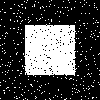

In [ ]:
rng = np.random.default_rng(42)         # 42: har safar bir xil tasodifiy sonlar
noise = rng.random(black_img.shape)
noisy_img = black_img.copy()
noisy_img[noise < 0.05] = 255           # <-- 0.05 ni o'zgartiring
noisy_img[noise > 0.95] = 0

# cv2_imshow yordamida sodda ko'rinishda chiqaramiz:
cv2_imshow(noisy_img)

## 7-qadam. Ikki filtr: Gauss va Median
**Vazifa:** `5` ni `3`, keyin `9` ga almashtiring (faqat toq son!). Qaysi filtr nuqtalarni yaxshiroq yo'qotadi? Kvadrat chetlari-chi?

In [ ]:
k = 5                                    # <-- 3, 5, 9 sinab ko'ring
gauss  = cv2.GaussianBlur(noisy_img, (k, k), 0)
median = cv2.medianBlur(noisy_img, k)

images = [noisy_img, gauss, median]
titles = ["Shovqinli", "Gauss", "Median"]
plt.figure(figsize=(12, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i]); plt.axis("off")
plt.tight_layout(); plt.show()

# Raqam bilan tekshiramiz: asl tasvirdan qancha piksel farq qiladi?
for name, im in [("Shovqinli", noisy_img), ("Gauss", gauss), ("Median", median)]:
    print(name, "- asl tasvirdan farq qilgan piksellar:", int(np.sum(im != black_img)))

## 8-qadam. O'z rasmingiz
Telefon rasmini yuklang (JPG/PNG). Yuklay olmasangiz, namuna rasm avtomatik olinadi.